Q1.

Executing on: cuda (NVIDIA GeForce RTX 4070 Laptop GPU)
Epoch [01/10] - Training Accuracy: 42.63% | Validation Accuracy: 51.82%
Epoch [02/10] - Training Accuracy: 56.59% | Validation Accuracy: 60.21%
Epoch [03/10] - Training Accuracy: 62.17% | Validation Accuracy: 62.91%
Epoch [04/10] - Training Accuracy: 65.79% | Validation Accuracy: 65.87%
Epoch [05/10] - Training Accuracy: 68.20% | Validation Accuracy: 68.41%
Epoch [06/10] - Training Accuracy: 70.40% | Validation Accuracy: 69.11%
Epoch [07/10] - Training Accuracy: 71.83% | Validation Accuracy: 69.70%
Epoch [08/10] - Training Accuracy: 73.23% | Validation Accuracy: 70.06%
Epoch [09/10] - Training Accuracy: 74.31% | Validation Accuracy: 71.02%
Epoch [10/10] - Training Accuracy: 75.02% | Validation Accuracy: 71.36%


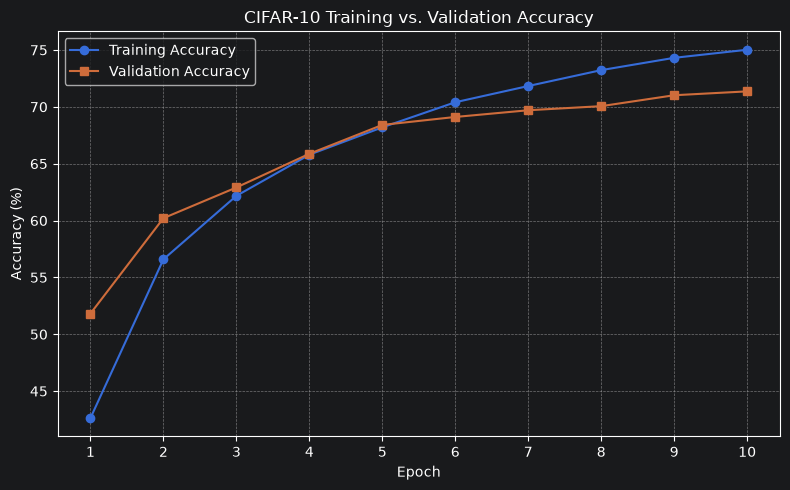

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# create cnn
class CIFAR10Model(nn.Module):
    def __init__(self):
        super(CIFAR10Model, self).__init__()

        # i. 2D conv, 64 filters, (5, 5), ReLU
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=5)
        self.relu1 = nn.ReLU()

        # ii. Max pooling, (2, 2)
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        # iii. 2D conv, 32 filters, (3, 3), ReLU
        self.conv2 = nn.Conv2d(in_channels=64, out_channels=32, kernel_size=3)
        self.relu2 = nn.ReLU()

        # iv. Max pooling, (2, 2)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        # v. 2D conv, 32 filters, (3, 3), ReLU
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3)
        self.relu3 = nn.ReLU()

        # vi. Flatten layer (32 * 4 * 4 = 512)
        self.flatten = nn.Flatten()

        # vii. Dense layer, 64 neurons, ReLU
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.relu4 = nn.ReLU()

        # viii. Output layer: 10 class logits
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.flatten(x)
        x = self.relu4(self.fc1(x))
        x = self.fc2(x)
        return x


# execution setup and training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# target cifar10 directory
local_cifar_root = r"C:\Users\joy\Documents\school\fall 2026\MANE 4961 ML\data"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 64
epochs = 10

trainset = torchvision.datasets.CIFAR10(
    root=local_cifar_root,
    train=True,
    download=False,
    transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

testset = torchvision.datasets.CIFAR10(
    root=local_cifar_root,
    train=False,
    download=False,
    transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

model = CIFAR10Model().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    model.train()
    correct_train = 0
    total_train = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_acc = 100.0 * correct_train / total_train
    train_accuracies.append(train_acc)

    # validation loop
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_acc = 100.0 * correct_val / total_val
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch + 1:02d}/{epochs:02d}] - Training Accuracy: {train_acc:.2f}% | Validation Accuracy: {val_acc:.2f}%")

# plot accuracies across the 10 epochs
plt.figure(figsize=(8, 5), dpi=100)
plt.plot(range(1, epochs + 1), train_accuracies, marker='o', label='Training Accuracy')
plt.plot(range(1, epochs + 1), val_accuracies, marker='s', label='Validation Accuracy')
plt.title('CIFAR-10 Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Q2.

In [3]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

required_features = ['worst compactness', 'worst concavity', 'worst area']

feature_indices = [np.where(feature_names == fname)[0][0] for fname in required_features]

X_filtered = X[:, feature_indices]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)
acc_linear = accuracy_score(y_test, y_pred_linear)

print(f"(a) Accuracy with Linear Kernel: {acc_linear:.4f} ({acc_linear*100:.2f}%)")

svm_rbf = SVC(kernel='rbf', C=2, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)

print(f"(b) Accuracy with RBF Kernel (C=2): {acc_rbf:.4f} ({acc_rbf*100:.2f}%)")


(a) Accuracy with Linear Kernel: 0.9912 (99.12%)
(b) Accuracy with RBF Kernel (C=2): 0.9649 (96.49%)
